<a href="https://colab.research.google.com/github/RohitSinghJethi/facial-emotion-recog/blob/main/facial_emotion_recognizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive
from pathlib import Path
import os
import zipfile

drive.mount('/content/drive')


FILE_PATH = Path('/content/drive/MyDrive/facial expreession.zip')

EXTRACT_DIR = Path('/content/fer_data')
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(FILE_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")
print(os.listdir(EXTRACT_DIR))

Mounted at /content/drive
Dataset extracted successfully!
['images']


In [6]:
EXTRACT_DIR = Path('/content/fer_data')

for path in EXTRACT_DIR.rglob('*'):
    if path.is_dir():
        print("Folder:", path)
    elif path.is_file():
        print("File:", path.name)

Streaming output truncated to the last 5000 lines.
File: 14270.jpg
File: 30198.jpg
File: 13255.jpg
File: 12738.jpg
File: 272.jpg
File: 10704.jpg
File: 24813.jpg
File: 13462.jpg
File: 16299.jpg
File: 10239.jpg
File: 14010.jpg
File: 136.jpg
File: 33937.jpg
File: 28781.jpg
File: 19176.jpg
File: 12169.jpg
File: 24666.jpg
File: 28602.jpg
File: 4190.jpg
File: 22938.jpg
File: 2895.jpg
File: 1774.jpg
File: 11779.jpg
File: 32714.jpg
File: 1000.jpg
File: 26808.jpg
File: 75.jpg
File: 6903.jpg
File: 28778.jpg
File: 17493.jpg
File: 9064.jpg
File: 19606.jpg
File: 10361.jpg
File: 1357.jpg
File: 20534.jpg
File: 605.jpg
File: 23545.jpg
File: 4282.jpg
File: 20480.jpg
File: 26513.jpg
File: 16343.jpg
File: 16241.jpg
File: 28323.jpg
File: 3155.jpg
File: 26342.jpg
File: 14413.jpg
File: 29476.jpg
File: 32213.jpg
File: 3379.jpg
File: 1472.jpg
File: 26523.jpg
File: 25278.jpg
File: 1912.jpg
File: 31553.jpg
File: 2104.jpg
File: 27895.jpg
File: 14678.jpg
File: 4266.jpg
File: 28874.jpg
File: 4228.jpg
File: 11505.j

Total images found: 71774


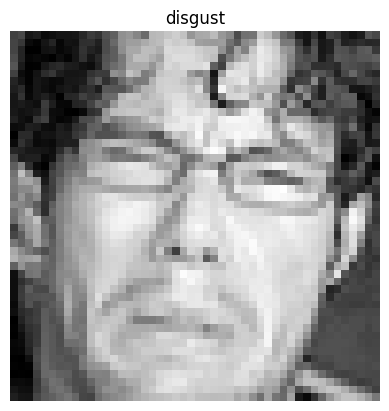

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

image_extensions = ['.jpg', '.jpeg', '.png', '.bmp']

images = [
    f for f in Path('/content/fer_data').rglob('*')
    if f.is_file() and f.suffix.lower() in image_extensions
]

print("Total images found:", len(images))

if images:
    img = Image.open(images[0])
    plt.imshow(img, cmap='gray')
    plt.title(images[0].parent.name)
    plt.axis('off')
    plt.show()

In [8]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

DATA_DIR = '/content/fer_data/images'

IMG_SIZE = (48, 48)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    f'{DATA_DIR}/train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode='grayscale',
    label_mode='int',
    shuffle=True,
    seed=42
)

val_ds = keras.utils.image_dataset_from_directory(
    f'{DATA_DIR}/validation',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode='grayscale',
    label_mode='int',
    shuffle=False
)

class_names = train_ds.class_names

print("Expression classes:", class_names)
print("Number of classes:", len(class_names))

train_ds = train_ds.map(
    lambda x, y: (x / 255.0, y),
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    lambda x, y: (x / 255.0, y),
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

Found 28821 files belonging to 7 classes.
Found 7066 files belonging to 7 classes.
Expression classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of classes: 7


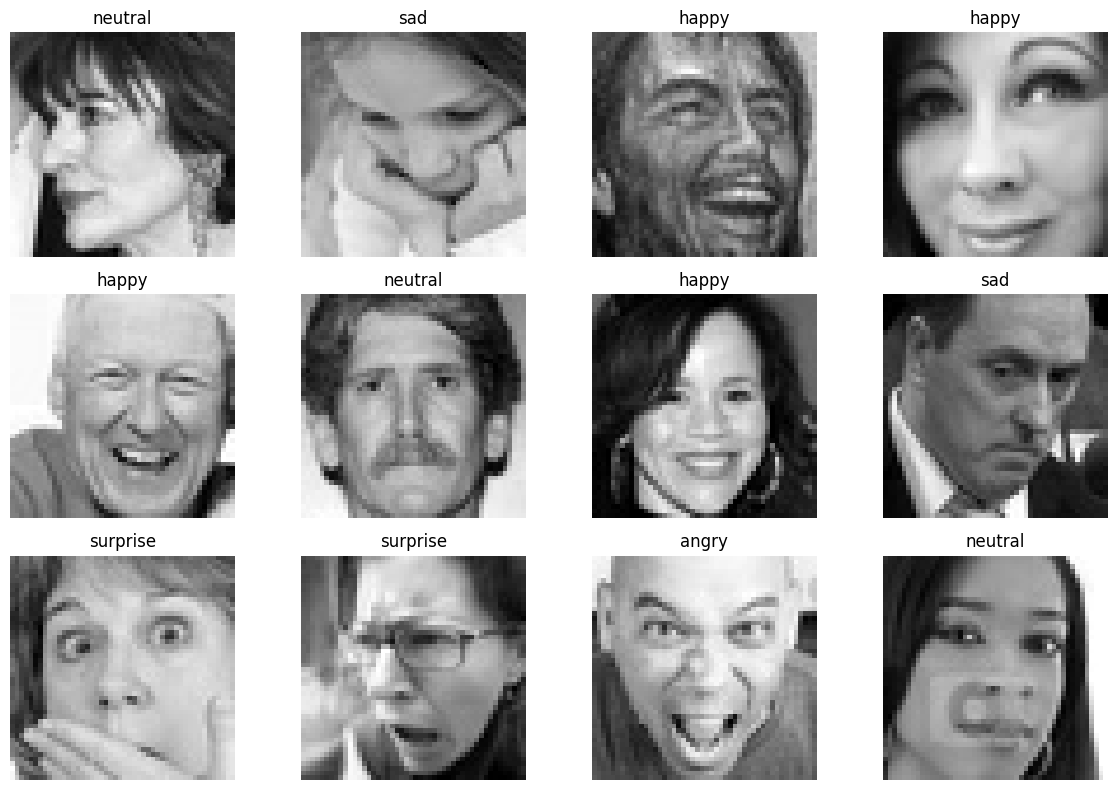

In [ ]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        plt.title(class_names[int(labels[i])])
        plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(48, 48, 1)),

    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(len(class_names), activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,535 (1.61 MB)

 Trainable params: 422,087 (1.61 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 280s 310ms/step - accuracy: 0.3751 - loss: 1.5684 - val_accuracy: 0.3651 - val_loss: 1.5487
Epoch 2/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 311s 299ms/step - accuracy: 0.4849 - loss: 1.3467 - val_accuracy: 0.4993 - val_loss: 1.2766
Epoch 3/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 270s 300ms/step - accuracy: 0.5386 - loss: 1.2134 - val_accuracy: 0.5502 - val_loss: 1.1940
Epoch 4/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 269s 299ms/step - accuracy: 0.5811 - loss: 1.1060 - val_accuracy: 0.5807 - val_loss: 1.1285
Epoch 5/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 273s 303ms/step - accuracy: 0.6192 - loss: 1.0070 - val_accuracy: 0.5511 - val_loss: 1.2230
Epoch 6/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 268s 297ms/step - accuracy: 0.6578 - loss: 0.9116 - val_accuracy: 0.4905 - val_loss: 1.4163
Epoch 7/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 277s 308ms/step - accuracy: 0.6983 - loss: 0.8094 - val_accuracy: 0.5542 - val_loss: 1.2720
Epoch 8/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 271s 300ms/step - accuracy: 0.7429 -

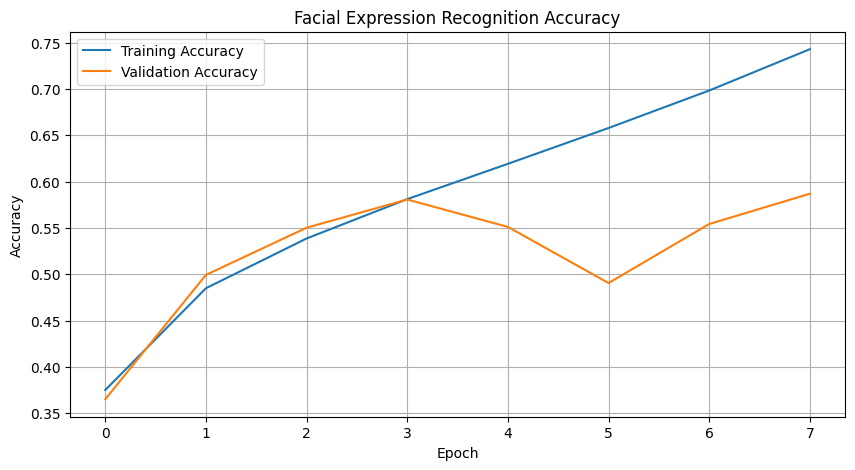

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        '/content/best_fer_model.keras',
        monitor='val_accuracy',
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)


plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Facial Expression Recognition Accuracy')
plt.legend()
plt.grid(True)
plt.show()




In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
import shutil

shutil.copy(
    '/content/best_fer_model.keras',
    '/content/drive/MyDrive/best_fer_model.keras'
)


with open('/content/drive/MyDrive/class_names.json', 'w') as f:
    json.dump(class_names, f)

print("Model and class names saved to Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model and class names saved to Google Drive.
